# **Exercise 1: Regression Task** - *Laptop Price Prediction*

# **Importing the Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv("/kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv")
print("Loaded:", "/kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv")
print("Rows:", len(data), "| Columns:", len(data.columns))

Loaded: /kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv
Rows: 1000 | Columns: 7


# **Exploring the Dataset**

In [3]:
data

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718
...,...,...,...,...,...,...,...
995,HP,3.343584,4,1000,12.587095,3.162399,31593.668017
996,Dell,2.780555,8,256,12.679356,3.750265,9149.521832
997,Dell,3.200569,4,512,12.666315,3.392612,16552.404779
998,Asus,1.604182,8,256,11.215581,3.857613,9407.473459


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Brand             1000 non-null   object 
 1   Processor_Speed   1000 non-null   float64
 2   RAM_Size          1000 non-null   int64  
 3   Storage_Capacity  1000 non-null   int64  
 4   Screen_Size       1000 non-null   float64
 5   Weight            1000 non-null   float64
 6   Price             1000 non-null   float64
dtypes: float64(4), int64(2), object(1)
memory usage: 54.8+ KB


In [5]:
data.head()

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718


In [6]:
data.tail()

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
995,HP,3.343584,4,1000,12.587095,3.162399,31593.668017
996,Dell,2.780555,8,256,12.679356,3.750265,9149.521832
997,Dell,3.200569,4,512,12.666315,3.392612,16552.404779
998,Asus,1.604182,8,256,11.215581,3.857613,9407.473459
999,Lenovo,1.711980,4,256,16.561498,3.440883,8807.696702


In [7]:
data.shape

(1000, 7)

# **Selection X and Y**

In [8]:
X = pd.get_dummies(data[['Brand', 'Processor_Speed', 'RAM_Size', 'Storage_Capacity', 'Screen_Size', 'Weight']], columns=['Brand'], drop_first=True)

In [9]:
X.head()

,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Brand_Asus,Brand_Dell,Brand_HP,Brand_Lenovo
0,3.830296,16,512,11.185147,2.641094,True,False,False,False
1,2.912833,4,1000,11.311372,3.260012,False,False,False,False
2,3.241627,4,256,11.853023,2.029061,False,False,False,True
3,3.806248,16,512,12.280360,4.573865,False,False,False,False
4,3.268097,32,1000,14.990877,4.193472,False,False,False,False


In [10]:
y = data['Price']

In [11]:
y.head()

0    17395.093065
1    31607.605919
2     9291.023542
3    17436.728334
4    32917.990718
Name: Price, dtype: float64

# **Splitting the Data**

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
print(f"Training set size: {len(X_train)}")

Training set size: 800


In [14]:
print(f"Testing set size: {len(X_test)}")

Testing set size: 200


# **Confirming the Split Sizes**

In [15]:
print("Training laptops:", len(X_train))
print("Training prices:", len(y_train))
print("Test laptops:", len(X_test))
print("Test prices:", len(y_test))

Training laptops: 800
Training prices: 800
Test laptops: 200
Test prices: 200


# **Building & Training the Model**

In [16]:
model = LinearRegression()

In [17]:
model.fit(X_train, y_train)

LinearRegression()

# **Model Testing**

In [18]:
price_prediction = model.predict(X_test)

In [19]:
price_prediction[:10]

array([10729.83078469, 31570.62488805,  9647.22523476,  9244.32591145,
       32026.00370899, 31649.24619225, 10338.06804952, 16962.46567984,
       18489.5888424 , 32374.14929353])

In [20]:
comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual price": y_test.to_numpy(),
    "Predicted price": price_prediction
})
comparison["Error"] = comparison["Actual price"] - comparison["Predicted price"]
comparison["Absolute error"] = comparison["Error"].abs()
display(comparison.head(10).round(2))

,Original row,Actual price,Predicted price,Error,Absolute error
0,521,10900.50,10729.83,170.67,170.67
1,737,31727.52,31570.62,156.89,156.89
2,740,9636.02,9647.23,-11.20,11.20
3,660,9412.60,9244.33,168.27,168.27
4,411,31641.11,32026.00,-384.90,384.90
5,678,31832.49,31649.25,183.24,183.24
6,626,10438.45,10338.07,100.38,100.38
7,513,17205.21,16962.47,242.74,242.74
8,859,18743.57,18489.59,253.98,253.98
9,136,32342.71,32374.15,-31.44,31.44


In [21]:
mse = mean_squared_error(y_test, price_prediction)
print(f"Test MSE: {mse:,.2f} squared price units")

Test MSE: 32,304.74 squared price units


In [22]:
mae = mean_absolute_error(y_test, price_prediction)
print(f"Test MAE: {mae:,.2f} average absolute price units")

Test MAE: 146.22 average absolute price units


In [23]:
r2 = r2_score(y_test, price_prediction)
print(f"Test r2: {r2:,.4f}")

Test r2: 0.9996


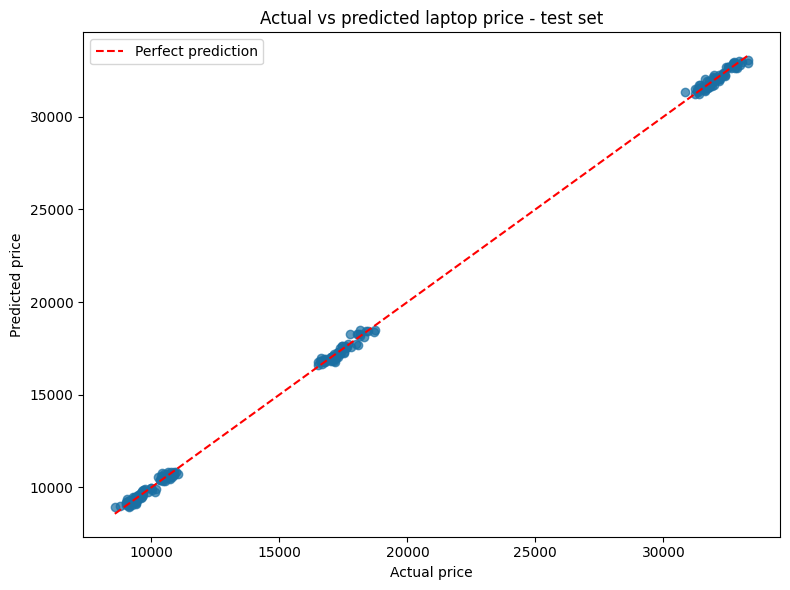

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, price_prediction, alpha=0.7, color="#1A6FA3")

lowest_price = min(y_test.min(), price_prediction.min())
highest_price = max(y_test.max(), price_prediction.max())
plt.plot(
    [lowest_price, highest_price], [lowest_price, highest_price],
    "r--", label="Perfect prediction"
)

plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted laptop price - test set")
plt.ticklabel_format(style="plain", axis="both")
plt.legend()
plt.tight_layout()
plt.show()

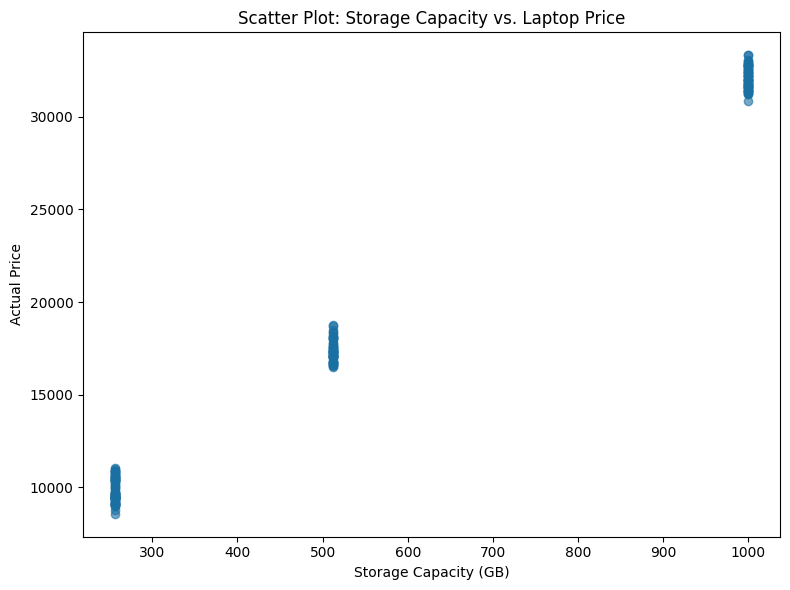

In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test["Storage_Capacity"], y_test, alpha=0.6, color="#1A6FA3")
plt.xlabel("Storage Capacity (GB)")
plt.ylabel("Actual Price")
plt.title("Scatter Plot: Storage Capacity vs. Laptop Price")
plt.tight_layout()
plt.show()

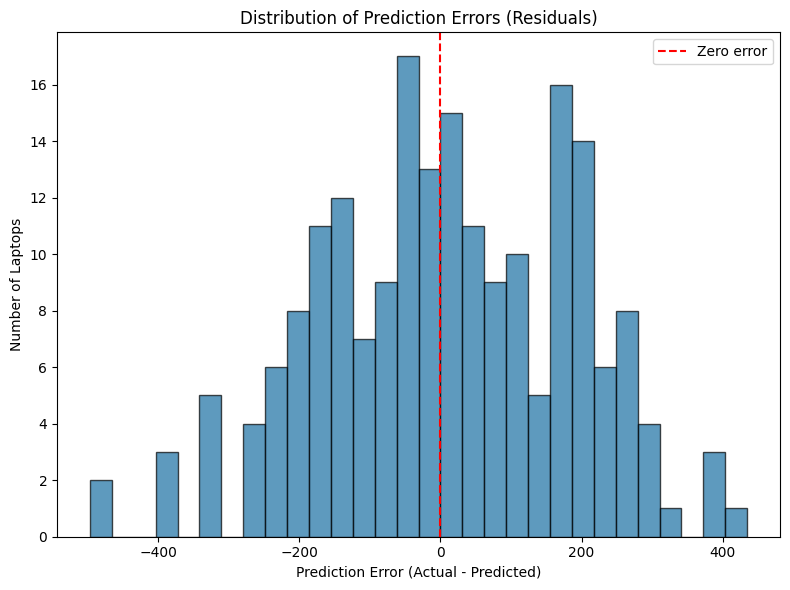

In [26]:
errors = y_test - price_prediction
plt.figure(figsize=(8, 6))
plt.hist(errors, bins=30, color="#1A6FA3", edgecolor="black", alpha=0.7)
plt.axvline(0, color="r", linestyle="--", label="Zero error")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Laptops")
plt.title("Distribution of Prediction Errors (Residuals)")
plt.legend()
plt.tight_layout()
plt.show()